# 06 – Phân tích Hồi quy OLS, Chẩn đoán 4 Giả định LINE & Điều hòa (Issue #12, W10)

**Môn học:** INFO3020 – Nhập môn Khoa học Dữ liệu (*Introduction to Data Science*) – ĐH CMC<br>
**Dữ liệu nguồn:** `data/processed/air_pollution_final.parquet` (Trạm NCEM/VEA 556 Nguyễn Văn Cừ, Hà Nội)<br>
**Mục tiêu nghiên cứu:** Mô hình hóa mối quan hệ quan sát giữa các yếu tố khí tượng bề mặt và nồng độ bụi mịn PM₂.₅, kiểm chứng toàn diện 4 giả định LINE trên phần dư, kiểm soát đa cộng tuyến qua chỉ số VIF, huấn luyện điều hòa Ridge/Lasso trên Train, và diễn giải hệ số $\beta$ phi nhân quả.

---

## Các Câu Hỏi Cốt Lõi của Tuần 10 (RQ3)

1. **Liên hệ Khí tượng & Ô nhiễm:** Trong điều kiện kiểm soát các yếu tố khác không đổi (*ceteris paribus*), nhiệt độ, độ ẩm, tốc độ gió và áp suất bề mặt liên hệ như thế nào với nồng độ PM₂.₅?
2. **Kiểm định Giả định LINE:** Liệu 4 giả định nền tảng của hồi quy OLS (Linearity, Independence, Normality, Equal Variance) có được thỏa mãn trên chuỗi thời gian thực nghiệm hay không?
3. **Đa cộng tuyến & Điểm đòn bẩy:** Chỉ số VIF cảnh báo điều gì về biến `pm10` và các biến thời tiết? Các điểm ngoại lai ảnh hưởng (Cook's distance) tác động ra sao?
4. **Điều hòa Ridge/Lasso:** Việc bổ sung điều hòa $L_1$ và $L_2$ (với siêu tham số được tune hoàn toàn trên Train) có cải thiện sai số trên tập Test độc lập không?


In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

warnings.filterwarnings("ignore")

# Cố định hạt giống ngẫu nhiên theo quy định toàn dự án
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Thiết lập đường dẫn thư mục gốc repo
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.regression import (
    DEFAULT_SPLIT_TIMESTAMP,
    compute_cooks_distance,
    compute_line_diagnostics,
    compute_vif,
    evaluate_models,
    prepare_regression_data,
    render_line_diagnostics_figure,
    run_regression_pipeline,
    tune_regularization,
)

DATA_PATH = REPO_ROOT / "data" / "processed" / "air_pollution_final.parquet"
FIG_PATH = REPO_ROOT / "figures" / "regression_line_diagnostics.png"

print(f"Data path: {DATA_PATH.resolve()}")
print(f"Tồn tại trên đĩa: {DATA_PATH.exists()}")


Data path: C:\Users\Huy Nguyen\orca\workspaces\air-pollution-analysis\M4-progress\data\processed\air_pollution_final.parquet
Tồn tại trên đĩa: True


## 1. Phân chia Train/Test theo Chuỗi Thời gian Tuyến tính

Kế thừa ranh giới phân chia từ Issue #7 (`2026-01-15 00:00:00+07:00`):
- Tập **Train**: Các quan sát trước `2026-01-15` (dùng để fit mô hình, tính VIF, chẩn đoán LINE và tune siêu tham số).
- Tập **Test**: Các quan sát từ `2026-01-15` trở đi (bảo lưu nguyên vẹn cho đánh giá độc lập cuối cùng).
- **Loại trừ biến `pm10`**: Do `corr(pm25, pm10) = 0.9727`, nếu đưa cả hai vào thì mô hình gặp hiện tượng đa cộng tuyến nghiêm trọng (VIF > 30).


In [2]:
df = pd.read_parquet(DATA_PATH)
X_train, y_train, X_test, y_test = prepare_regression_data(
    df, split_timestamp=DEFAULT_SPLIT_TIMESTAMP, drop_collinear_pm10=True
)

print(f"Số dòng Train có target hợp lệ: {len(X_train):,} dòng")
print(f"Số dòng Test có target hợp lệ:  {len(X_test):,} dòng")
print(f"Tổng số quan sát hồi quy:       {len(X_train) + len(X_test):,} dòng")
print(f"Danh sách biến giải thích ({X_train.shape[1]}): {list(X_train.columns)}")


Số dòng Train có target hợp lệ: 4,279 dòng
Số dòng Test có target hợp lệ:  3,216 dòng
Tổng số quan sát hồi quy:       7,495 dòng
Danh sách biến giải thích (9): ['temperature', 'relative_humidity', 'wind_speed', 'precipitation', 'surface_pressure', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']


## 2. Khảo sát Biến đổi Mục tiêu Ứng viên $Y = \log(1 + \text{PM}_{2.5})$

Phân phối nồng độ PM₂.₅ có độ lệch phải mạnh ($Skewness > 1.2$). Ta đánh giá xem biến đổi $Y = \log(1 + \text{PM}_{2.5})$ trên tập Train có giúp cải thiện độ đối xứng của phần dư sau khớp hay không.


In [3]:
X_train_const = sm.add_constant(X_train)
ols_orig = sm.OLS(y_train, X_train_const).fit()

log_y_train = np.log1p(y_train)
ols_log = sm.OLS(log_y_train, X_train_const).fit()

print(f"Mô hình Gốc   (PM2.5):     R² Train = {ols_orig.rsquared:.4f} | Resid Skewness = {ols_orig.resid.skew():.3f}")
print(f"Mô hình Log1p (log(1+PM)): R² Train = {ols_log.rsquared:.4f} | Resid Skewness = {ols_log.resid.skew():.3f}")
print("\nNhận xét: Phần dư mô hình gốc có độ lệch phải nhẹ (skew = +0.554). Biến đổi log1p làm đảo chiều")
print("và tăng độ lệch tuyệt đối (|skew| = 0.959, lệch trái với đuôi dài ở giá trị thấp).")
print("Do đó, log1p không cải thiện tính đối xứng của phần dư, đồng thời làm phức tạp hóa việc diễn giải")
print("trực tiếp hệ số theo đơn vị chuẩn µg/m³. Vì vậy, mô hình chính thức giữ nguyên đơn vị gốc.")


Mô hình Gốc   (PM2.5):     R² Train = 0.3747 | Resid Skewness = 0.554
Mô hình Log1p (log(1+PM)): R² Train = 0.2987 | Resid Skewness = -0.959

Nhận xét: Phần dư mô hình gốc có độ lệch phải nhẹ (skew = +0.554). Biến đổi log1p làm đảo chiều
và tăng độ lệch tuyệt đối (|skew| = 0.959, lệch trái với đuôi dài ở giá trị thấp).
Do đó, log1p không cải thiện tính đối xứng của phần dư, đồng thời làm phức tạp hóa việc diễn giải
trực tiếp hệ số theo đơn vị chuẩn µg/m³. Vì vậy, mô hình chính thức giữ nguyên đơn vị gốc.


## 3. Chẩn đoán Đa Cộng Tuyến qua Chỉ số VIF (Variance Inflation Factor)

Theo quy tắc heuristic, $\text{VIF} > 5.0$ là tín hiệu cảnh báo về mối tương quan mạnh giữa các biến giải thích.


In [4]:
df_vif = compute_vif(X_train)
print("Bảng chỉ số VIF trên tập Train (đã loại trừ pm10):")
display(df_vif)

high_vif = df_vif[df_vif["VIF"] > 5.0]
print(f"\nSố biến có VIF > 5.0: {len(high_vif)} ({list(high_vif['Feature'])})")
print("Áp suất bề mặt và nhiệt độ có VIF dao động quanh 7-8 do quy luật nhiệt động lực học khí quyển đối lưu.")


Bảng chỉ số VIF trên tập Train (đã loại trừ pm10):


,Feature,VIF
0,surface_pressure,8.061175
1,temperature,7.654865
2,month_cos,4.469999
3,relative_humidity,2.455866
4,month_sin,2.300676
5,hour_cos,2.062612
6,hour_sin,1.403734
7,wind_speed,1.137773
8,precipitation,1.130370



Số biến có VIF > 5.0: 2 (['surface_pressure', 'temperature'])
Áp suất bề mặt và nhiệt độ có VIF dao động quanh 7-8 do quy luật nhiệt động lực học khí quyển đối lưu.


## 4. Ước lượng Mô hình OLS & Bảng Tham số

Huấn luyện mô hình OLS đa biến trên tập Train bằng `statsmodels.api.OLS`:
$$ \text{PM}_{2.5} = \beta_0 + \sum_{j=1}^{p} \beta_j X_j + \varepsilon $$


In [5]:
print(ols_orig.summary())


                            OLS Regression Results                            
Dep. Variable:                   pm25   R-squared:                       0.375
Model:                            OLS   Adj. R-squared:                  0.373
Method:                 Least Squares   F-statistic:                     284.3
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:42:53   Log-Likelihood:                -19663.
No. Observations:                4279   AIC:                         3.935e+04
Df Residuals:                    4269   BIC:                         3.941e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const               309.9997    139.73

## 5. Chẩn đoán 4 Giả định LINE trên Phần Dư

1. **L – Linearity (Tuyến tính):** Phần dư có kỳ vọng bằng 0 không phụ thuộc vào giá trị dự báo $\hat{y}$.
2. **I – Independence (Độc lập):** Kiểm tra tự tương quan chuỗi thời gian qua hệ số Durbin-Watson ($DW$) và hàm tự tương quan ACF.
3. **N – Normality (Phân phối chuẩn):** Phần dư có tuân theo phân phối chuẩn $N(0, \sigma^2)$ hay không qua Q-Q plot và kiểm định Jarque-Bera.
4. **E – Equal Variance (Phương sai đồng nhất):** Kiểm tra hiện tượng phương sai thay đổi qua kiểm định Breusch-Pagan Lagrange Multiplier.


In [6]:
line_diag = compute_line_diagnostics(ols_orig, X_train, y_train, max_lags=48)

print("KẾT QUẢ CHẨN ĐOÁN 4 GIẢ ĐỊNH LINE:")
print(f"1. Linearity:       Resid Mean = {line_diag.residuals_mean:.6f} | Corr(Resid, Fitted) = {line_diag.residuals_fitted_corr:.6f}")
print(f"2. Independence:    Durbin-Watson = {line_diag.durbin_watson:.4f} (DW < 1.0 -> Tự tương quan dương rất mạnh)")
print(f"3. Normality:       Jarque-Bera = {line_diag.jarque_bera_stat:.1f} (p = {line_diag.jarque_bera_pvalue:.2e}) | Skew = {line_diag.skewness:.3f}, Kurt = {line_diag.kurtosis:.3f}")
print(f"4. Equal Variance:  Breusch-Pagan LM = {line_diag.breusch_pagan_stat:.1f} (p = {line_diag.breusch_pagan_pvalue:.2e} -> Bác bỏ Homoscedasticity)")

print("\nKẾT LUẬN QUAN TRỌNG: Dữ liệu chuỗi thời gian vi phạm nghiêm trọng giả định Independence và Equal Variance.")
print("Do đó, các sai số chuẩn OLS thông thường bị sai lệch và không thể dùng R² để suy diễn năng lực ngoại suy.")


KẾT QUẢ CHẨN ĐOÁN 4 GIẢ ĐỊNH LINE:
1. Linearity:       Resid Mean = 0.000000 | Corr(Resid, Fitted) = 0.000000
2. Independence:    Durbin-Watson = 0.2430 (DW < 1.0 -> Tự tương quan dương rất mạnh)
3. Normality:       Jarque-Bera = 392.7 (p = 5.32e-86) | Skew = 0.554, Kurt = 0.988
4. Equal Variance:  Breusch-Pagan LM = 658.3 (p = 6.44e-136 -> Bác bỏ Homoscedasticity)

KẾT LUẬN QUAN TRỌNG: Dữ liệu chuỗi thời gian vi phạm nghiêm trọng giả định Independence và Equal Variance.
Do đó, các sai số chuẩn OLS thông thường bị sai lệch và không thể dùng R² để suy diễn năng lực ngoại suy.


## 6. Điểm Đòn bẩy & Ảnh hưởng qua Khoảng cách Cook (Cook's Distance)

Nhận diện các mốc thời gian có ảnh hưởng bất thường đến hệ số hồi quy: ngưỡng heuristic $D_i > 4/n$.


In [7]:
cooks_d, thresh, n_inf = compute_cooks_distance(ols_orig)
print(f"Ngưỡng Cook's Distance (4/n): {thresh:.6f}")
print(f"Giá trị Cook's Distance cực đại: {np.max(cooks_d):.6f}")
print(f"Số điểm vượt ngưỡng đòn bẩy: {n_inf:,} / {len(y_train):,} ({n_inf / len(y_train):.2%})")


Ngưỡng Cook's Distance (4/n): 0.000935
Giá trị Cook's Distance cực đại: 0.017413
Số điểm vượt ngưỡng đòn bẩy: 267 / 4,279 (6.24%)


## 7. Điều hòa Ridge ($L_2$) & Lasso ($L_1$) với TimeSeriesSplit (Leak-Free CV)

Dò tìm siêu tham số $\alpha$ hoàn toàn trên tập Train thông qua 5-fold `TimeSeriesSplit` cross-validation (tuyệt đối không dùng tập Test để tune). Để đảm bảo không rò rỉ dữ liệu, bộ chuẩn hóa `RobustScaler` được fit độc lập trên phần huấn luyện của từng fold.


In [8]:
alphas = np.logspace(-3, 3, 50)
best_ridge_alpha, best_lasso_alpha, ridge_mod, lasso_mod, scaler_mod = tune_regularization(
    X_train, y_train, n_splits=5, alphas=alphas
)

print(f"Siêu tham số tối ưu Ridge: alpha = {best_ridge_alpha:.4f}")
print(f"Siêu tham số tối ưu Lasso: alpha = {best_lasso_alpha:.4f}")


Siêu tham số tối ưu Ridge: alpha = 754.3120
Siêu tham số tối ưu Lasso: alpha = 1.5264


## 8. Đánh giá Độc lập trên Tập TEST & Luận giải Khoa học $R^2 < 0$

So sánh hiệu năng dự báo giữa Baseline (Dummy Mean), OLS, Ridge và Lasso trên tập Test độc lập.


In [9]:
metrics_df, ols_sk = evaluate_models(X_train, y_train, X_test, y_test, ridge_mod, lasso_mod, scaler=scaler_mod)
print("BẢNG SO SÁNH HIỆU NĂNG MÔ HÌNH TRÊN TẬP TEST:")
display(metrics_df)

print("\n--- LUẬN GIẢI KHOA HỌC VỀ KẾT QUẢ R² ÂM TRÊN TẬP TEST ---")
print("1. Hiện tượng: Các mô hình OLS/Ridge/Lasso tĩnh có R² âm trên tập Test (-1.75 đến -2.02),")
print("   dự báo kém hơn Baseline hằng số trung bình (Dummy R² = -0.0280).")
print("2. Bản chất: Chuỗi thời gian PM2.5 có tính tự tương quan cực mạnh (DW = 0.243, rho1 ≈ 0.76).")
print("   Mô hình tĩnh chỉ sử dụng các yếu tố khí tượng tức thời mà không có các biến trễ tự hồi quy (lag PM2.5)")
print("   nên không thể nắm bắt được quán tính tích tụ ô nhiễm khi dịch chuyển mùa từ Train sang Test.")
print("3. Ý nghĩa: Đây là phát hiện thực nghiệm hợp lệ chứng minh giới hạn của hồi quy tĩnh trên chuỗi thời gian,")
print("   tạo cơ sở tất yếu cho mô hình chuỗi thời gian có đặc trưng trễ (Issue #13).")


BẢNG SO SÁNH HIỆU NĂNG MÔ HÌNH TRÊN TẬP TEST:


,Model,MAE (µg/m³),RMSE (µg/m³),R²,Adjusted R²
0,Baseline (Dummy Mean),18.91,24.46,-0.0280,-0.0280
1,OLS Linear Regression,37.32,41.46,-1.9540,-1.9623
2,Ridge (alpha=754.312),35.89,39.97,-1.7457,-1.7534
3,Lasso (alpha=1.526),38.02,41.91,-2.0182,-2.0267



--- LUẬN GIẢI KHOA HỌC VỀ KẾT QUẢ R² ÂM TRÊN TẬP TEST ---
1. Hiện tượng: Các mô hình OLS/Ridge/Lasso tĩnh có R² âm trên tập Test (-1.75 đến -2.02),
   dự báo kém hơn Baseline hằng số trung bình (Dummy R² = -0.0280).
2. Bản chất: Chuỗi thời gian PM2.5 có tính tự tương quan cực mạnh (DW = 0.243, rho1 ≈ 0.76).
   Mô hình tĩnh chỉ sử dụng các yếu tố khí tượng tức thời mà không có các biến trễ tự hồi quy (lag PM2.5)
   nên không thể nắm bắt được quán tính tích tụ ô nhiễm khi dịch chuyển mùa từ Train sang Test.
3. Ý nghĩa: Đây là phát hiện thực nghiệm hợp lệ chứng minh giới hạn của hồi quy tĩnh trên chuỗi thời gian,
   tạo cơ sở tất yếu cho mô hình chuỗi thời gian có đặc trưng trễ (Issue #13).


## 9. Diễn giải Hệ số $\beta$ theo Chuẩn 3 Nghĩa vụ (HAC Newey-West)

Theo nguyên tắc liêm chính học thuật INFO3020, việc diễn giải hệ số hồi quy phải tuân thủ nghiêm ngặt 3 nghĩa vụ:
1. **Liên hệ quan sát (*Associated with*):** Tuyệt đối không dùng từ ngữ mang tính nhân quả như "gây ra", "dẫn đến", "làm tăng".
2. **Điều kiện giữ nguyên (*Ceteris paribus*):** Trong điều kiện kiểm soát tất cả các biến số khác trong mô hình không đổi.
3. **Giới hạn trong miền giá trị quan sát:** Không ngoại suy ra ngoài dải thời tiết thực nghiệm của Hà Nội.

Do giả định Độc lập và Phương sai đồng nhất bị vi phạm, bảng dưới đây đối chứng sai số chuẩn kinh điển và **sai số chuẩn HAC (Newey-West với 24 lags)**.


In [10]:
ols_hac = sm.OLS(y_train, X_train_const).fit(cov_type="HAC", cov_kwds={"maxlags": 24})

coef_table = pd.DataFrame({
    "Biến giải thích": ols_orig.params.index,
    "Hệ số Beta": ols_orig.params.values.round(4),
    "SE (Kinh điển)": ols_orig.bse.values.round(4),
    "p-value (Kinh điển)": ols_orig.pvalues.apply(lambda p: f"{p:.4e}" if p < 0.0001 else f"{p:.4f}"),
    "SE (HAC-24)": ols_hac.bse.values.round(4),
    "p-value (HAC-24)": ols_hac.pvalues.apply(lambda p: f"{p:.4e}" if p < 0.0001 else f"{p:.4f}"),
    "95% CI (HAC)": [f"[{l:.2f}, {u:.2f}]" for l, u in zip(ols_hac.conf_int()[0], ols_hac.conf_int()[1])]
})
print("BẢNG HỆ SỐ HỒI QUY ĐỐI CHỨNG (CLASSICAL vs. HAC NEWEY-WEST 24 LAGS):")
display(coef_table)


BẢNG HỆ SỐ HỒI QUY ĐỐI CHỨNG (CLASSICAL vs. HAC NEWEY-WEST 24 LAGS):


,Biến giải thích,Hệ số Beta,SE (Kinh điển),p-value (Kinh điển),SE (HAC-24),p-value (HAC-24),95% CI (HAC)
const,const,309.9997,139.7387,0.0266,589.6235,0.5991,"[-845.64, 1465.64]"
temperature,temperature,0.1664,0.1984,0.4017,0.7805,0.8312,"[-1.36, 1.70]"
relative_humidity,relative_humidity,0.0638,0.0407,0.1173,0.1219,0.6005,"[-0.18, 0.30]"
wind_speed,wind_speed,-6.0673,0.3029,2.2683e-85,1.1173,5.6256e-08,"[-8.26, -3.88]"
precipitation,precipitation,-0.9471,0.3448,0.0060,0.5424,0.0808,"[-2.01, 0.12]"
surface_pressure,surface_pressure,-0.2450,0.1345,0.0685,0.5659,0.6651,"[-1.35, 0.86]"
hour_sin,hour_sin,3.5160,0.6141,1.1004e-08,1.2907,0.0064,"[0.99, 6.05]"
hour_cos,hour_cos,3.4884,0.7454,2.9605e-06,1.4025,0.0129,"[0.74, 6.24]"
month_sin,month_sin,28.8563,1.2786,1.2201e-106,5.0855,1.3928e-08,"[18.89, 38.82]"
month_cos,month_cos,12.3294,1.1395,6.1493e-27,3.9078,0.0016,"[4.67, 19.99]"


### Diễn giải Định tính Hệ số $\beta$ trong Miền Giá trị Quan sát Thực nghiệm

1. **Tốc độ gió (`wind_speed`, dải quan sát [0,00; 9,55] m/s):**
   - $\beta = -6,0673$ ($p_{\text{HAC}} = 5,63 \times 10^{-8} < 0,001$).
   - *Diễn giải:* Trong dải tốc độ gió từ 0,00 đến 9,55 m/s, mỗi khi tốc độ gió tăng thêm 1 m/s, nồng độ PM₂.₅ trung bình giờ **liên hệ với mức giảm 6,07 µg/m³** trong điều kiện các yếu tố khí tượng và chu kỳ thời gian khác được giữ không đổi (*ceteris paribus*). Kết quả này phản ánh cơ chế vật lý về sự phát tán và thông gió khí quyển.
2. **Lượng mưa (`precipitation`, dải quan sát [0,00; 20,50] mm):**
   - $\beta = -0,9471$ ($p_{\text{Kinh điển}} = 0,0060$, nhưng $p_{\text{HAC}} = 0,0808 > 0,05$).
   - *Diễn giải:* Trong dải lượng mưa từ 0,00 đến 20,50 mm, mỗi 1 mm mưa liên hệ với mức giảm 0,95 µg/m³ PM₂.₅ (*ceteris paribus*). Tuy nhiên, dưới sai số chuẩn HAC Newey-West kiểm soát tự tương quan 24 giờ, mối liên hệ này có $p > 0,05$, cho thấy không đủ bằng chứng thống kê vững chắc để khẳng định hiệu ứng độc lập.
3. **Nhiệt độ, Độ ẩm & Áp suất bề mặt:**
   - Cả 3 biến khí tượng đều có $p_{\text{HAC}} > 0,05$, không có bằng chứng thống kê về mối liên hệ tuyến tính độc lập trong điều kiện *ceteris paribus*.
4. **Chu kỳ thời gian ngày đêm & mùa vụ:**
   - Giữ ý nghĩa thống kê rất mạnh ($p < 0,01$), phản ánh nhịp sinh học giao thông đô thị và hiện tượng nghịch nhiệt mùa đông tại Hà Nội.


## 10. Xuất Bản Biểu Đồ Ấn Phẩm Chẩn Đoán LINE (300 DPI)


Đã lưu biểu đồ ấn phẩm: C:\Users\Huy Nguyen\orca\workspaces\air-pollution-analysis\M4-progress\figures\regression_line_diagnostics.png


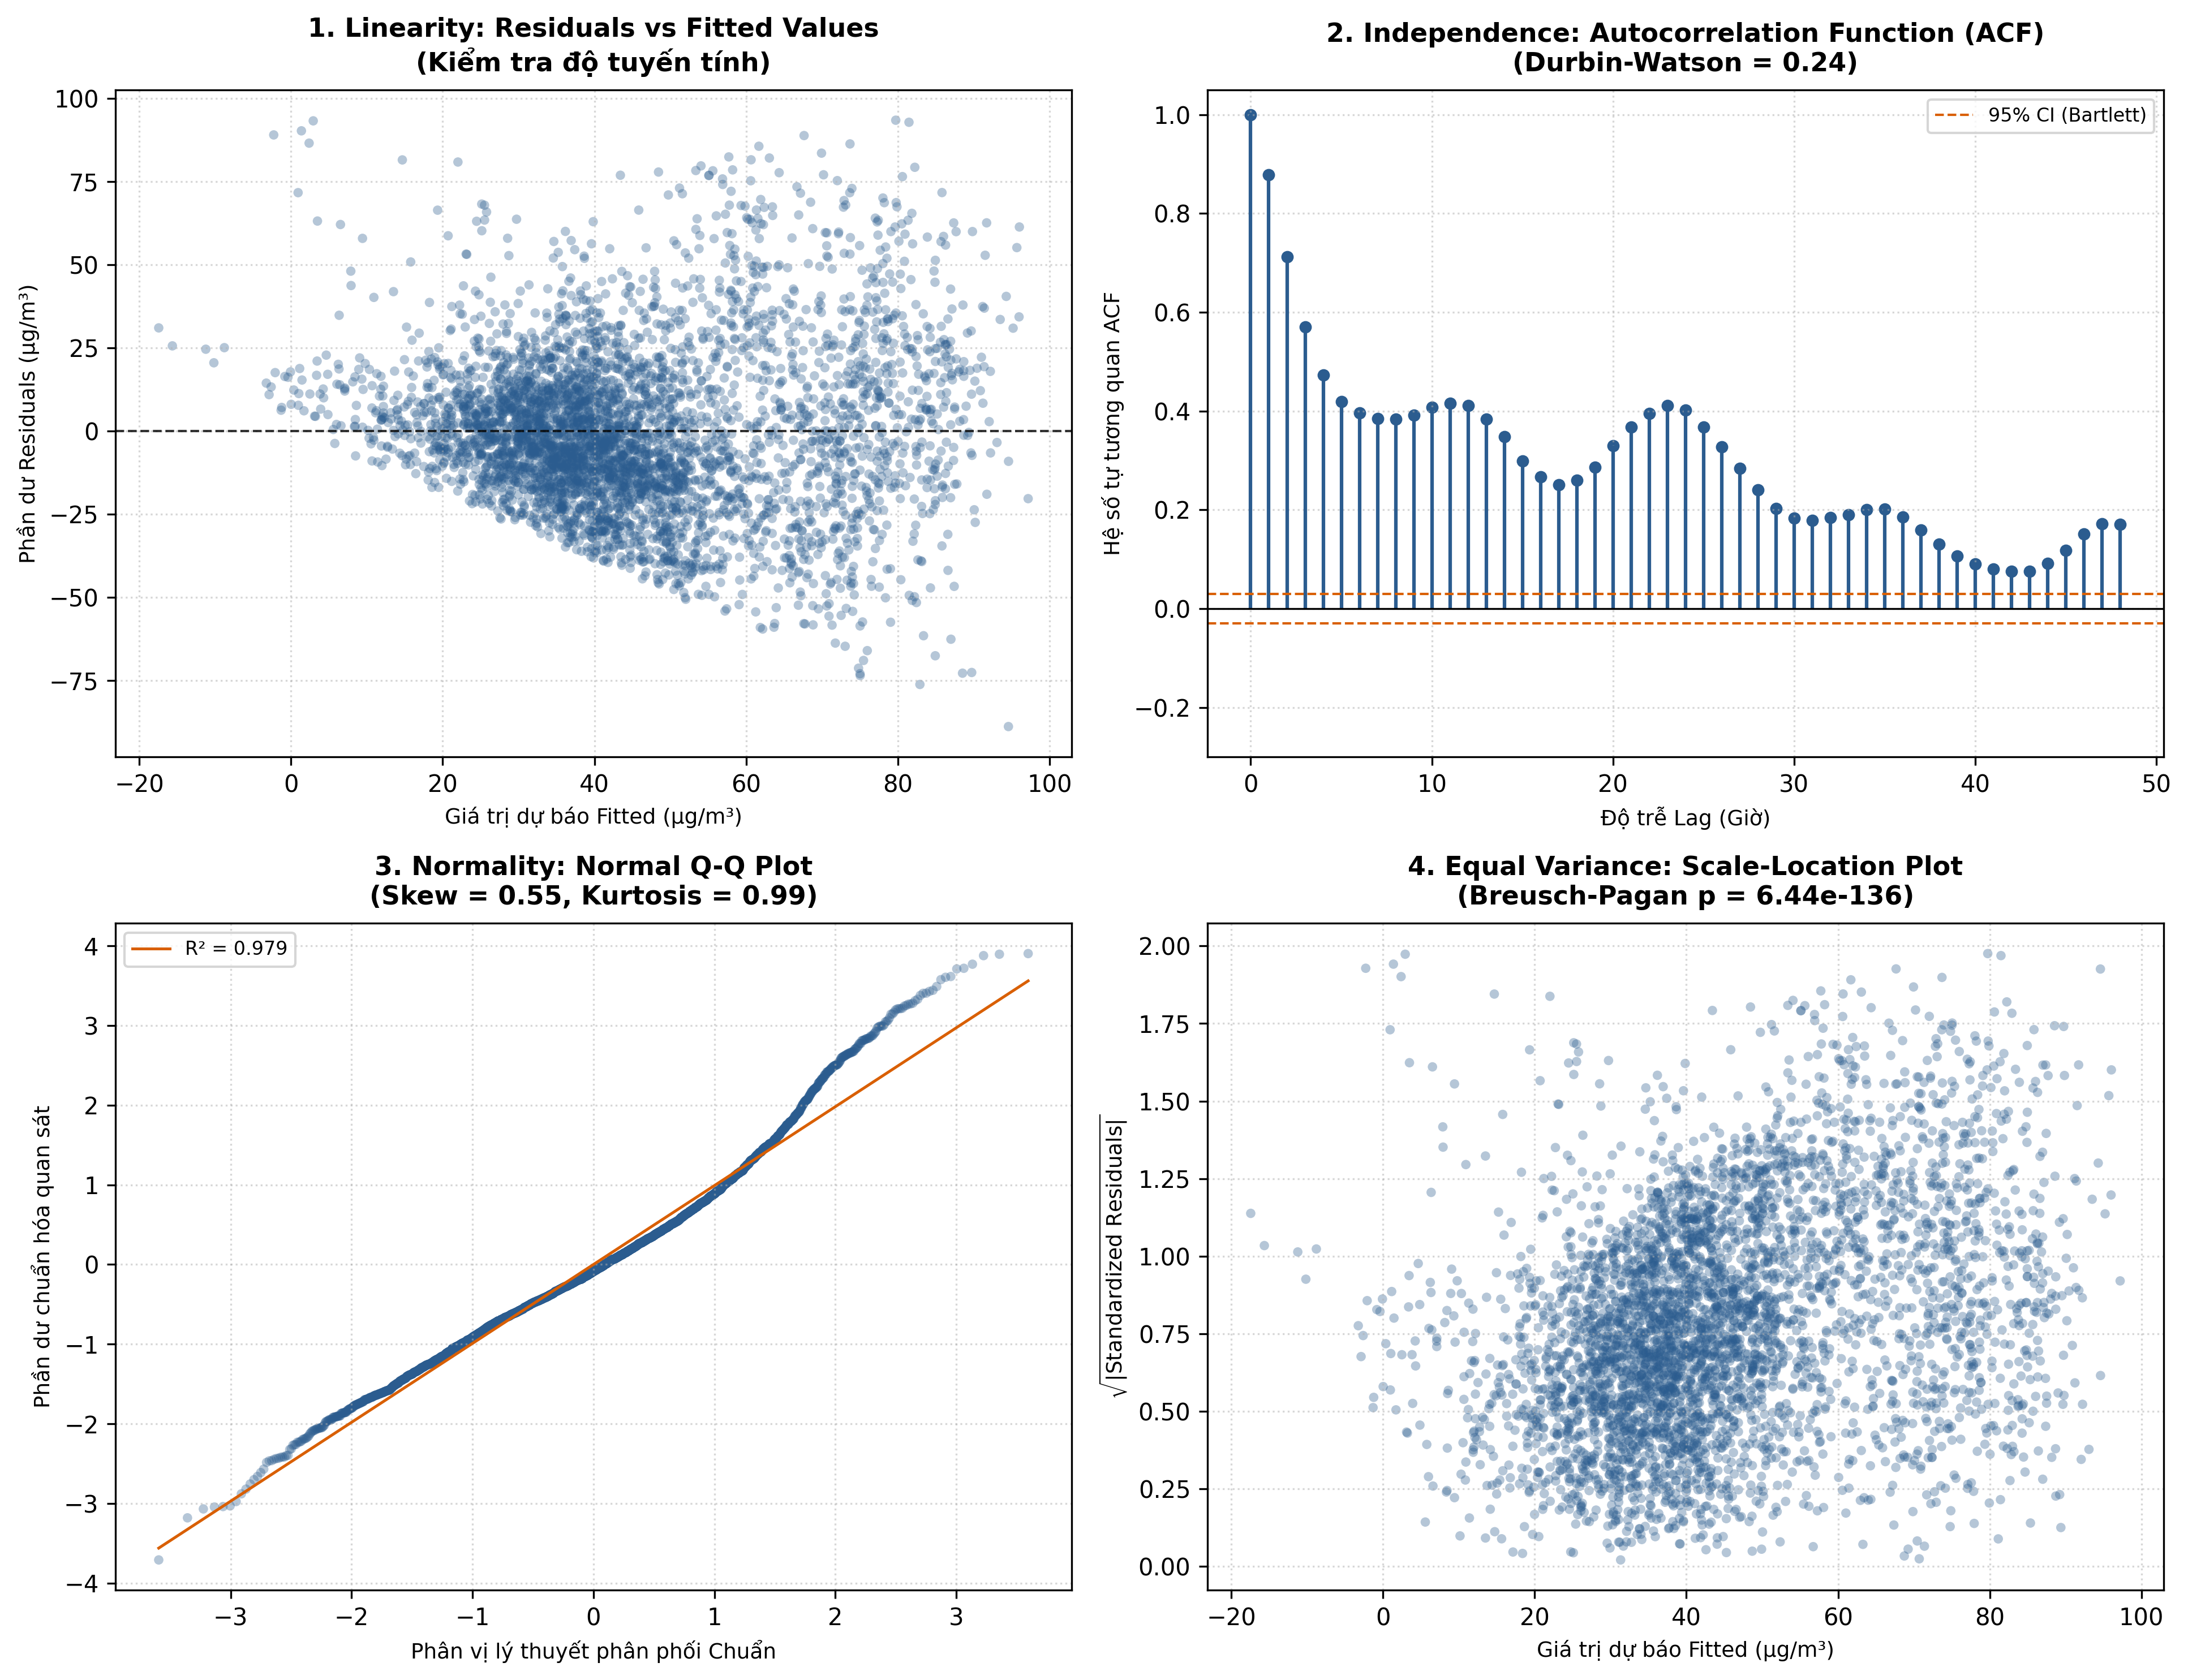

In [11]:
render_line_diagnostics_figure(ols_orig, line_diag, FIG_PATH)
print(f"Đã lưu biểu đồ ấn phẩm: {FIG_PATH.resolve()}")

from IPython.display import Image
Image(filename=str(FIG_PATH))


## 11. Xuất Bản Báo Cáo Nghiệm Thu `reports/regression_results.md`


In [12]:
from src.regression import write_regression_report, RegressionResults

results = RegressionResults(
    split_timestamp=DEFAULT_SPLIT_TIMESTAMP,
    n_train=len(y_train),
    n_test=len(y_test),
    predictors=list(X_train.columns),
    vif_table=df_vif,
    ols_summary_str=str(ols_orig.summary()),
    hac_summary_str=str(ols_hac.summary()),
    coefficients=coef_table,
    line_diagnostics=line_diag,
    cooks_distance_max=float(np.max(cooks_d)),
    cooks_distance_threshold=thresh,
    n_influential_points=n_inf,
    ridge_best_alpha=best_ridge_alpha,
    lasso_best_alpha=best_lasso_alpha,
    metrics_table=metrics_df,
    log1p_target_evaluated=True,
    log1p_metrics={"original_resid_skew": float(ols_orig.resid.skew()), "log1p_resid_skew": float(ols_log.resid.skew())},
)

report_path = REPO_ROOT / "reports" / "regression_results.md"
write_regression_report(results, report_path)
print(f"Đã xuất báo cáo nghiệm thu: {report_path.resolve()}")


Đã xuất báo cáo nghiệm thu: C:\Users\Huy Nguyen\orca\workspaces\air-pollution-analysis\M4-progress\reports\regression_results.md
